## Lab 4: Working with 'real' data
Introduction

In this lab we are going to work on how to estimate the background from 'real' data. Real is in air quotes because the data is actually from simplified simulations to make the problems manageable in a single lab. But the data will have some features that resemble that of real data sets.

Getting data and HD5

In general exchanging raw data is a pain. Writing data in text files is error prone, inaccurate, and wastes space, but raw binary files have all sorts of subtleties too (including the internal byte order of your processor). To try and sidestep a whole set of nasty issues, we are going to use HDF5 (originally developed by the National Center for Supercomputing Applications for data exchange) to allow everyone to import the data. HDF5 has become a prefered way for projects to save and exchange data.

You will need to install the h5py library. At the top of your notebook you should then have an import that looks like:

In [2]:
%matplotlib inline
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats
import h5py


hf = h5py.File('../Shared/gammaray_lab4.h5', 'r')
hf.keys()

data = np.array(hf.get('data'))

np.shape(data)
data[:,0]

hf.close()


### Problem

In this problem we are looking at the data from a gamma-ray satellite orbiting in low Earth orbit. It takes a reading of the number of particles detected every 100 milliseconds, and is in an approximately 90 minute orbit. While it is looking for gamma-ray bursts, virtually all of the particles detected are background cosmic rays.

As with most data, there are 'features.' Your lab instructor has helpfully incorporated the meta-data into your data file.

1. Examine the data. The columns are time (in gps seconds), Solar phase (deg) showing the position of the sun relative to the orbit, Earth longitude (deg) giving the position of the spacecraft relative to the ground, and particle counts. Make a few plots, generally exploring your data and making sure you understand it. Give a high level description of the data features you see. Specifically comment on whether you see signal contamination in your data, and how you plan to build a background pdf().

2. The background is not consistent across the dataset. Find and describe as accurately as you can how the background changes.

3. Create a model for the background that includes time dependence, and explicitly compare your model to the data. How good is your model of the background?

4. Because the background varies, your discovery sensitivity threshold (how many particles you would need to see) also varies. What is the '5-sigma' threshold for a 100 millisecond GRB at different times?

5. While this is simulated data, it is based on a real effect seen by low Earth orbit satellites. Can you identify the cause of the variable background and propose a physical model?

### Checking out Counts relative to time

We want to look at the first 10000 points of data


In [3]:
print(data[1][4000000])

324.1255144032948


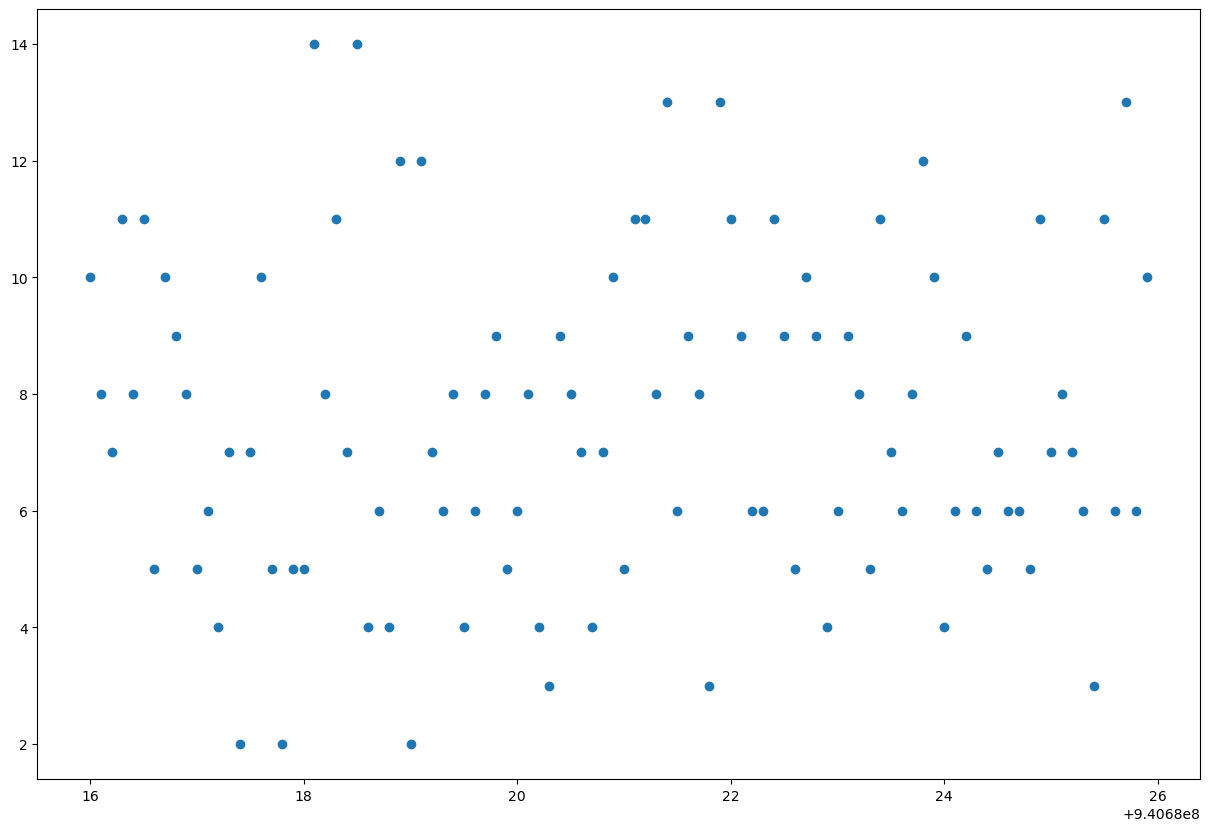

In [4]:
# scatter plot of counts vs time

plt.rcParams["figure.figsize"] = (15,10)

idx = 100

t = data[0][0:idx]

counts = data[3][0:idx]

fig, ax = plt.subplots(1, 1)
plt.scatter(t, counts)

plt.show()

Potential gamma ray burst at around 30 counts? 

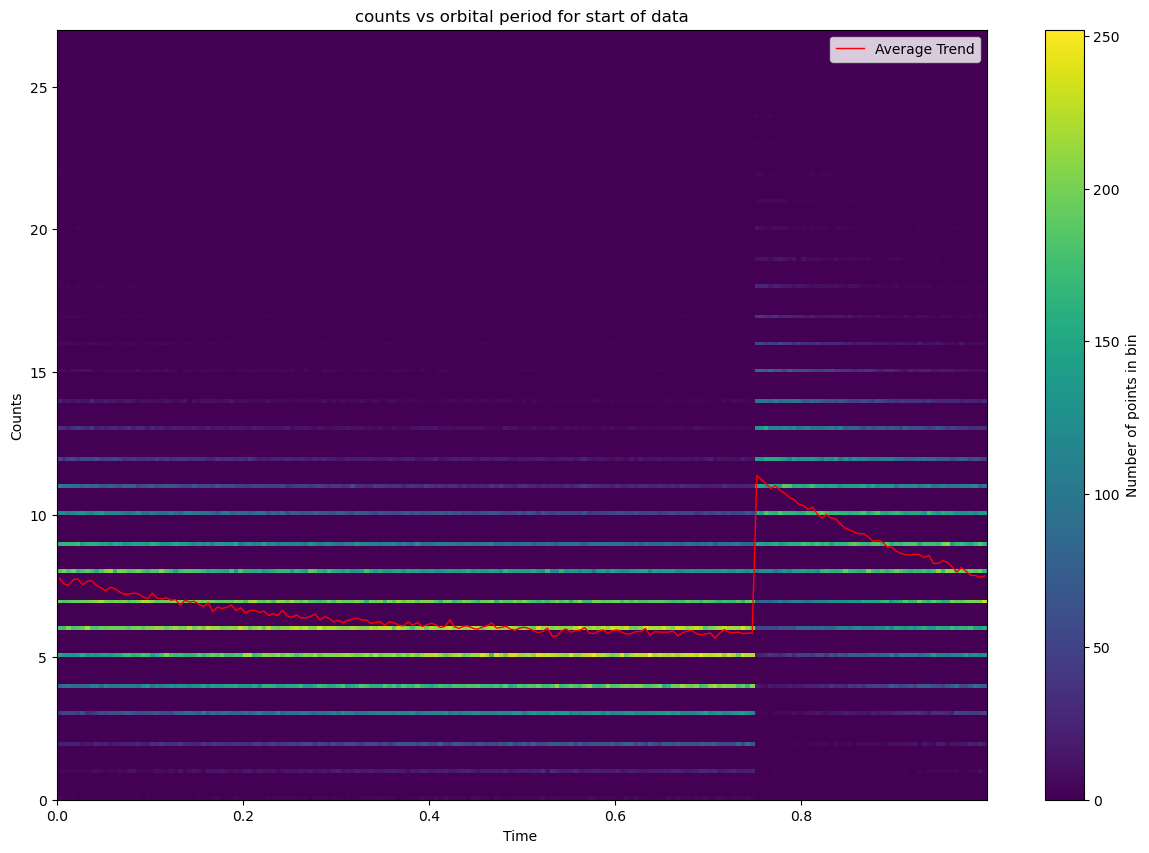

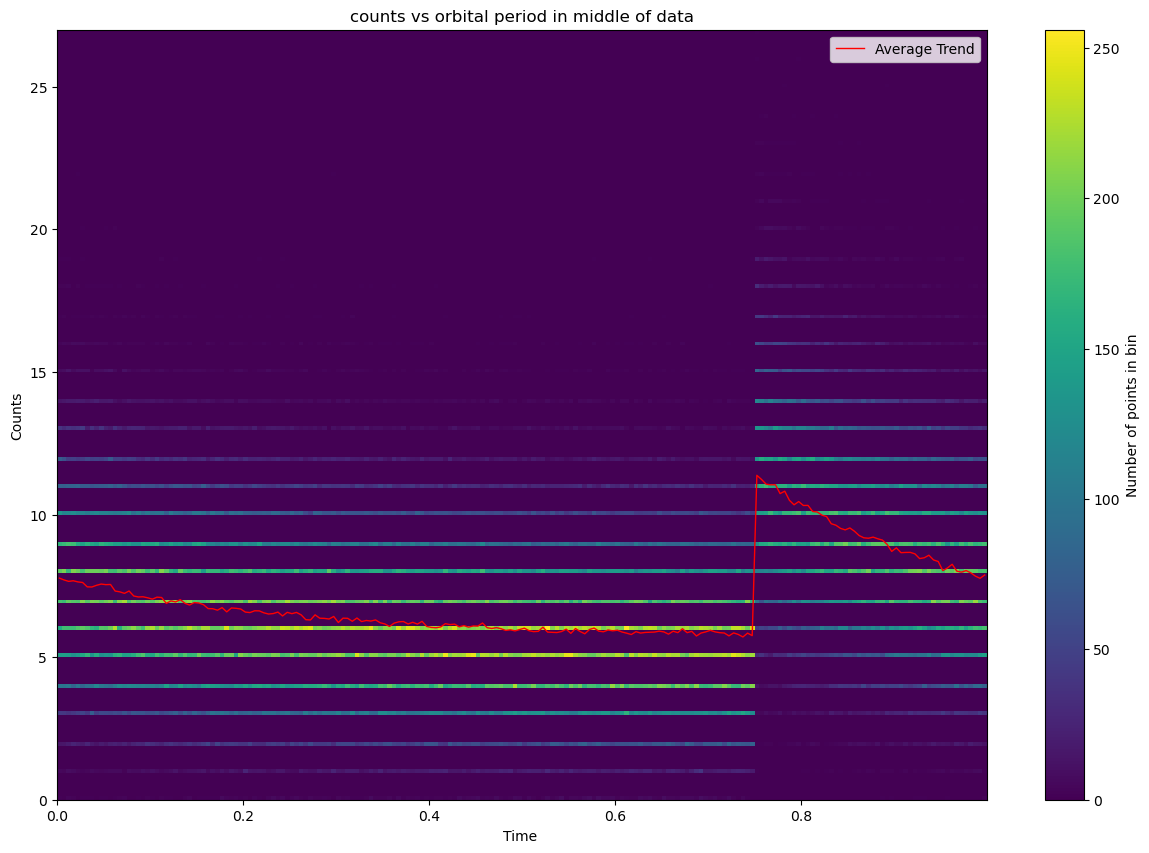

In [5]:

# 2d histogram plot of counts vs orbital period for first 5 orbits folded into 1 period

plt.rcParams["figure.figsize"] = (15,10)

idx_5_orbits = 90*60*10*5

t_5_orbits = data[0][0:idx_5_orbits] - data[0][0]

counts = data[3][0:idx_5_orbits]

t_orbit_folded = (t_5_orbits / (60*90) % 1)

# --- 2D Histogram Plot of counts vs time ---
num_bins = 200

fig, ax = plt.subplots(1, 1)
hb = ax.hist2d(t_orbit_folded, counts, bins=num_bins, cmap='viridis')
fig.colorbar(hb[3], ax=ax, label='Number of points in bin')

bin_means, bin_edges, _ = stats.binned_statistic(
    t_orbit_folded, counts, statistic='mean', bins=num_bins
)

bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

ax.plot(bin_centers, bin_means, color='red', linewidth=1.0, label='Average Trend')

ax.set_xlabel('Time ')
ax.set_ylabel('Counts')
ax.set_title('counts vs orbital period for start of data')
ax.legend(loc='upper right')
plt.show()

# scatter plot of counts vs orbital period for 5 orbits halfway into the data

start_idx = data.shape[1] // 2

idx_5_orbits = 90*60*10*5 + start_idx

t_5_orbits = data[0][start_idx:idx_5_orbits] - data[0][start_idx]

counts = data[3][start_idx:idx_5_orbits]

t_orbit_folded = (t_5_orbits / (60*90) % 1)

# --- 2D Histogram Plot of counts vs time ---
num_bins = 200

fig, ax = plt.subplots(1, 1)
hb = ax.hist2d(t_orbit_folded, counts, bins=num_bins, cmap='viridis')
fig.colorbar(hb[3], ax=ax, label='Number of points in bin')

bin_means, bin_edges, _ = stats.binned_statistic(
    t_orbit_folded, counts, statistic='mean', bins=num_bins
)

bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

ax.plot(bin_centers, bin_means, color='red', linewidth=1.0, label='Average Trend')

ax.set_xlabel('Time ')
ax.set_ylabel('Counts')
ax.set_title('counts vs orbital period in middle of data')
ax.legend(loc='upper right')
plt.show()

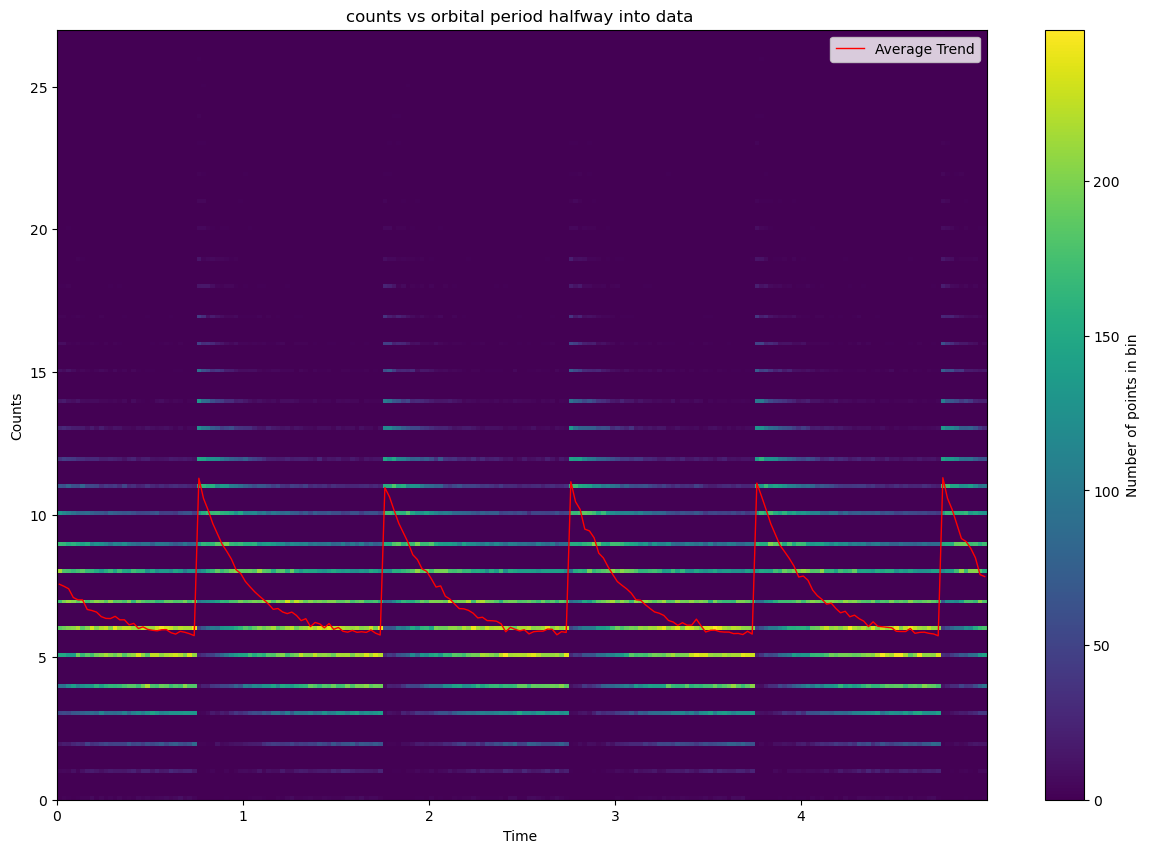

In [6]:
# scatter plot of counts vs orbital period for 5 orbits halfway in the data

start_idx = data.shape[1] // 2

idx_5_orbits = 90*60*10*5 + start_idx

t_5_orbits = data[0][start_idx:idx_5_orbits] - data[0][start_idx]

counts = data[3][start_idx:idx_5_orbits]

t_orbit_folded = (t_5_orbits / (60*90) % 5)

# --- 2D Histogram Plot of counts vs time ---
num_bins = 200

fig, ax = plt.subplots(1, 1)
hb = ax.hist2d(t_orbit_folded, counts, bins=num_bins, cmap='viridis')
fig.colorbar(hb[3], ax=ax, label='Number of points in bin')

bin_means, bin_edges, _ = stats.binned_statistic(
    t_orbit_folded, counts, statistic='mean', bins=num_bins
)

bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

ax.plot(bin_centers, bin_means, color='red', linewidth=1.0, label='Average Trend')

ax.set_xlabel('Time ')
ax.set_ylabel('Counts')
ax.set_title('counts vs orbital period halfway into data ')
ax.legend(loc='upper right')
plt.show()

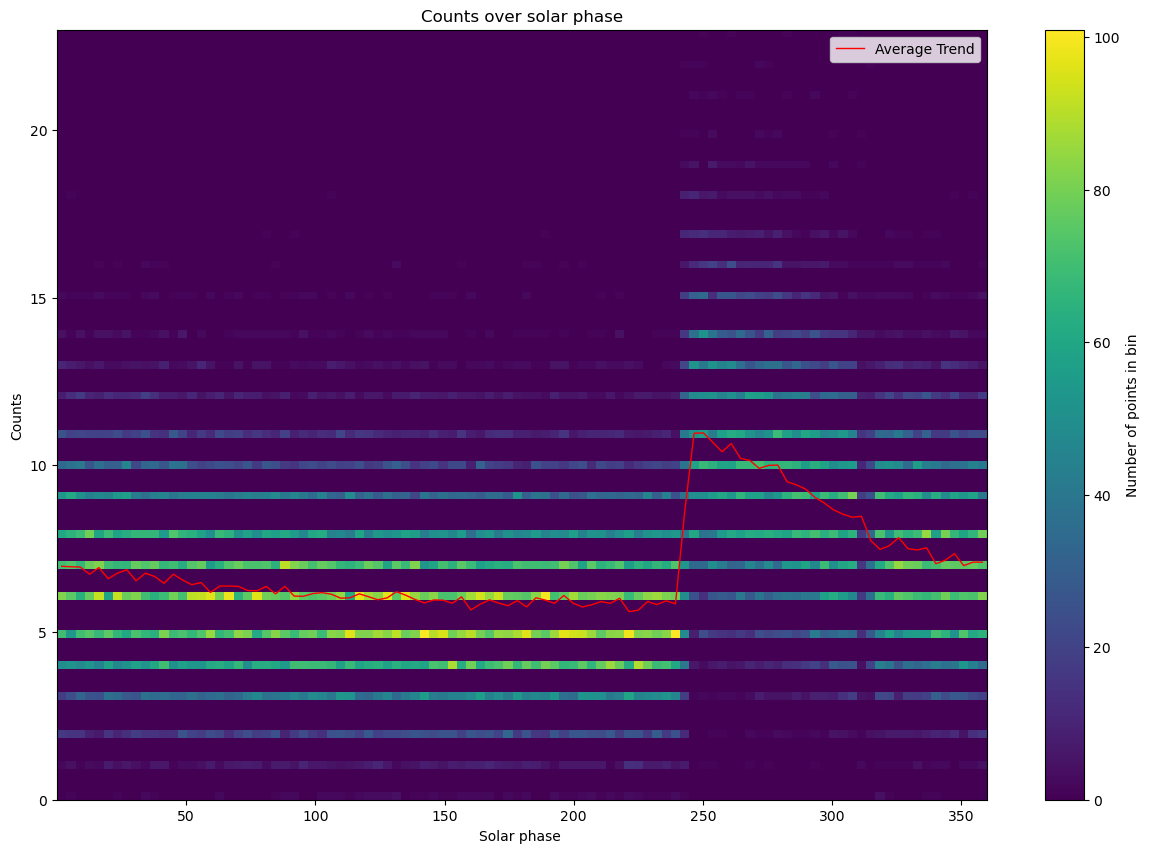

In [17]:
# 2d histogram plot of counts vs solar phase

start_idx = 0
idx_solar = 50000 + start_idx

solar_phase = data[1][start_idx:idx_solar]

counts = data[3][start_idx:idx_solar]

# --- 2D Histogram Plot of counts vs time ---
num_bins = 100

fig, ax = plt.subplots(1, 1)
hb = ax.hist2d(solar_phase, counts, bins=num_bins, cmap='viridis')
fig.colorbar(hb[3], ax=ax, label='Number of points in bin')

bin_means, bin_edges, _ = stats.binned_statistic(
    solar_phase, counts, statistic='mean', bins=num_bins
)

bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

ax.plot(bin_centers, bin_means, color='red', linewidth=1.0, label='Average Trend')

ax.set_xlabel('Solar phase ')
ax.set_ylabel('Counts')
ax.set_title('Counts over solar phase')
ax.legend(loc='upper right')
plt.show()


In [47]:
# looking at the same small section of the orbital period over the entire dataset

points_between_samples = 90*60*10
start_idx = int(.7 * 90*60*10)

t_min_periodic = data[0][::points_between_samples]
c_period_min = data[3][::points_between_samples]

fig, ax = plt.subplots(1, 1)
plt.scatter(t_min_periodic, c_period_min)

plt.show()

ValueError: cannot reshape array of size 25920001 into shape (100)

#### 1a) 

Examine the data. The columns are time (in gps seconds), Solar phase (deg) showing the position of the sun relative to the orbit, Earth longitude (deg) giving the position of the spacecraft relative to the ground, and particle counts. Make a few plots, generally exploring your data and making sure you understand it. Give a high level description of the data features you see. Specifically comment on whether you see signal contamination in your data, and how you plan to build a background pdf().

Answer:

Features:

Signal contamination:

How to build background PDF:

for the background, the background appears to be well described by a poisson distribution with some average rate that changes over the orbital period. So we could build a pdf by finding the average number of counts used in a poisson distribution. This average value decays exponentially with each orbit and then resets, so we would use a dynamic mean rate that decays and then resets for our background. 



#### 1b)
The background is not consistent across the dataset. Find and describe as accurately as you can how the background changes.

Answer: The background changes with the orbital period, which can be described as a decaying exponential mean rate of counts for a poisson distribution. 

